In [3]:
# Installing the Box2D environment for physics simulation
!pip install gymnasium
!pip install swig
!pip install gymnasium[box2d]
!pip install gymnasium[other]

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [1]:
# Updating the package list and installing necessary packages for the project
!sudo apt-get install -y cmake
# Updating the package list and installing ffmpeg and freeglut3-dev for visualization, xvfb for virtual display
!sudo apt-get install -y ffmpeg freeglut3-dev xvfb

# Installing the Stable Baselines3 library for reinforcement learning along with extra dependencies
!pip install "stable-baselines3[extra]>=2.0.0a4"

Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app
Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
# Importing required libraries and modules
import os
import gymnasium as gym  # Importing gym library as gymnasium

# Printing the version of gym library
print(f"{gym.__version__=}")
import base64
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import stable_baselines3

# Printing the version of stable_baselines3 library
print(f"{stable_baselines3.__version__=}")
from stable_baselines3 import DQN
from IPython import display as ipythondisplay
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.results_plotter import load_results, ts2xy
from stable_baselines3.common.vec_env import VecVideoRecorder, DummyVecEnv

# Setting up a fake display for video rendering
os.system("Xvfb :1 -screen 0 1024x768x24 &")
os.environ['DISPLAY'] = ':1'


gym.__version__='1.4.0'


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


stable_baselines3.__version__='2.9.0'


## Define a callback to store model on interval (for checkpointing)

In [4]:
# Defining a callback class to save the model at specified intervals
class SaveOnIntervalCallback(BaseCallback):
    def __init__(self, save_interval: int, save_path: str, verbose=1):
        super().__init__(verbose)
        self.save_interval = save_interval  # Setting the interval of saving
        self.save_path = save_path  # Setting the path to save models

    def _on_step(self) -> bool:
        # Saving the model if the current timestep is a multiple of the save interval
        if self.num_timesteps % self.save_interval == 0:
            save_file = os.path.join(self.save_path, f'model_{self.num_timesteps}')  # Defining the file name for the model
            self.model.save(save_file)  # Saving the model
            if self.verbose > 0:
                print(f'Saving model to {save_file}.zip')  # Printing a message on successful save
        return True


In [5]:
# Creating directories for storing logs and models
log_dir = "cartpoleDQN/gym/"  # Directory for storing training logs
models_dir = "cartpoleDQN/models/"  # Directory for storing models

# Ensuring the directories exist or creating them
os.makedirs(log_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

## Initialise the Gym environment

In [6]:
# Creating and wrapping the environment with a monitor for logging
env = gym.make("CartPole-v1")  # Creating the environment
env = Monitor(env, log_dir)  # Wrapping the environment with a monitor for logging

## Utility Functions

### Record Video

In [7]:
# Function to record videos of the agent's performance
def record_video(env_id, model, video_length=1000, prefix="", video_folder="cartpoleDQN/videos/"):
    eval_env = DummyVecEnv([lambda: gym.make(env_id, render_mode='rgb_array')])  # Creating a dummy environment for recording
    eval_env = VecVideoRecorder(
        eval_env,
        video_folder=video_folder,
        record_video_trigger=lambda step: step == 0,
        video_length=video_length,
        name_prefix=prefix,
    )
    obs = eval_env.reset()  # Resetting the environment
    for _ in range(video_length):
        action, _ = model.predict(obs, deterministic=True)
        obs, _, _, _ = eval_env.step(action)  # Taking a step in the environment
    eval_env.close()  # Closing the evaluation environment

### Show Video

In [8]:
# Defining functions for video recording and displaying

# Function to display recorded videos
def show_videos(video_path="", prefix=""):
    html = []
    # Reading and encoding videos to display
    for mp4 in Path(video_path).glob("{}*.mp4".format(prefix)):
        video_b64 = base64.b64encode(mp4.read_bytes())
        html.append(
            '''<video alt="{0}" autoplay
                      loop controls style="height: 400px;">
                <source src="data:video/mp4;base64,{1}" type="video/mp4" />
            </video>'''.format(mp4, video_b64.decode('ascii'))
        )
    ipythondisplay.display(ipythondisplay.HTML(data="<br>".join(html)))  # Displaying the videos

### Initialise the callback

In [9]:
# Instantiating and training the DQN agent with callback for saving
save_interval = 200000  # Setting save interval to save three models: at the beginning, middle, and end of training
callback = SaveOnIntervalCallback(save_interval, save_path=models_dir)  # Initializing the callback


## Define Custom Feature Extractor and Create DQN Model

In [10]:
import torch as th
import torch.nn as nn

from stable_baselines3.common.torch_layers import BaseFeaturesExtractor

class CustomANN(BaseFeaturesExtractor):
    def __init__(self, observation_space, features_dim=128):
        super().__init__(observation_space, features_dim)

        input_dim = observation_space.shape[0]

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, features_dim),
            nn.ReLU()
        )

    def forward(self, observations):
        return self.network(observations)

policy_kwargs = dict(
    features_extractor_class=CustomANN,
    features_extractor_kwargs=dict(features_dim=64),
    net_arch=[128, 128]
)

In [11]:
model = DQN(
    "MlpPolicy",
    env,
    verbose=1,
    batch_size=128,
    buffer_size=50000,
    exploration_final_eps=0.05,
    exploration_fraction=0.20,
    gamma=0.99,
    gradient_steps=-1,
    learning_rate=0.0001,
    learning_starts=1000,
    target_update_interval=1000,
    train_freq=4,
    policy_kwargs=policy_kwargs
)

Using cuda device
Wrapping the env in a DummyVecEnv.


## Train the Agent

In [ ]:
model.learn(total_timesteps=1000000, callback=callback)  # Training the agent

# Saving the final model
model.save(os.path.join(models_dir, "model_final"))  # Saving the final model

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 21.8     |
|    ep_rew_mean      | 21.8     |
|    exploration_rate | 1        |
| time/               |          |
|    episodes         | 4        |
|    fps              | 4126     |
|    time_elapsed     | 0        |
|    total_timesteps  | 87       |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 22.1     |
|    ep_rew_mean      | 22.1     |
|    exploration_rate | 0.999    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 5346     |
|    time_elapsed     | 0        |
|    total_timesteps  | 177      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 21.8     |
|    ep_rew_mean      | 21.8     |
|    exploration_rate | 0.999    |
| time/               |          |
|    episodes         | 12       |
|    fps              | 6196     |
|    time_elapsed     | 0        |
|    total_timesteps  | 261      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 26.9     |
|    ep_rew_mean      | 26.9     |
|    exploration_rate | 0.998    |
| time/               |          |
|    episodes       

In [12]:
# Functions for analyzing the trained models

# Function to get the identifiers of saved models
def get_model_identifiers(models_dir):
    files = os.listdir(models_dir)

    identifiers = []

    for f in files:
        if f.startswith("model_") and f != "model_final.zip":
            identifier = f.replace("model_", "").replace(".zip", "")
            if identifier.isdigit():
                identifiers.append(int(identifier))

    return sorted(identifiers)

# Function to find key identifiers (earliest, middle, final)
def find_key_identifiers(identifiers):
    earliest = identifiers[0]
    middle = identifiers[len(identifiers) // 2]
    final = identifiers[-1]

    return earliest, middle, final

# Function to view videos of the models at different training stages
def view(models_dir):
    identifiers = get_model_identifiers(models_dir)  # Getting model identifiers
    earliest, middle, final = find_key_identifiers(identifiers)  # Finding key identifiers

    # Recording and displaying videos at the beginning, middle, and end of training
    for stage, identifier in zip(["beginning", "middle", "end"], [earliest, middle, final]):
        model_path = os.path.join(models_dir, f'model_{identifier}')  # Forming the model path
        model = DQN.load(model_path)  # Loading the model
        record_video("CartPole-v1", model, video_length=1000, prefix=f'dqn-cartpole-{stage}')  # Recording video
        show_videos("cartpoleDQN/videos/", prefix=f'dqn-cartpole-{stage}')  # Showing videos

In [13]:
view(models_dir)  # Calling the view function

Saving video to d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-beginning-step-0-to-step-1000.mp4
MoviePy - Building video d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-beginning-step-0-to-step-1000.mp4.
MoviePy - Writing video d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-beginning-step-0-to-step-1000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-beginning-step-0-to-step-1000.mp4


Saving video to d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-middle-step-0-to-step-1000.mp4
MoviePy - Building video d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-middle-step-0-to-step-1000.mp4.
MoviePy - Writing video d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-middle-step-0-to-step-1000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-middle-step-0-to-step-1000.mp4


Saving video to d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-end-step-0-to-step-1000.mp4
MoviePy - Building video d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-end-step-0-to-step-1000.mp4.
MoviePy - Writing video d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-end-step-0-to-step-1000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\cartpoleDQN\videos\dqn-cartpole-end-step-0-to-step-1000.mp4


## Plot the learning curve

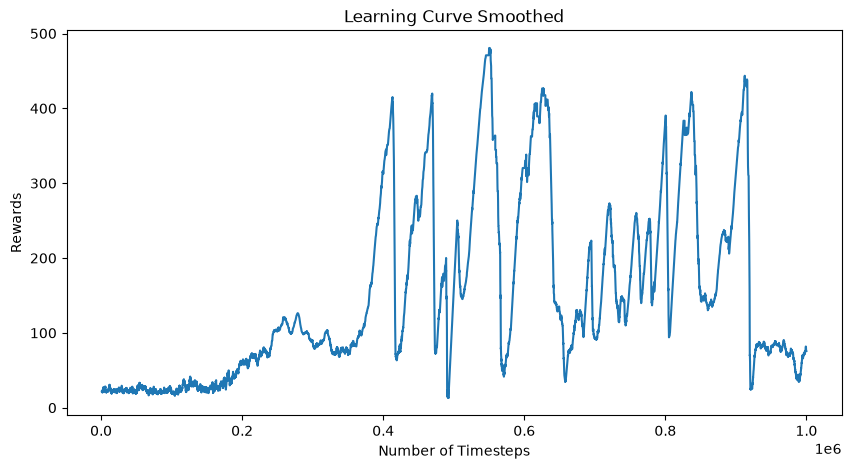

In [15]:
# Function for plotting the learning curve of the agent
def plot_results(log_folder, title="Learning Curve"):
    x, y = ts2xy(load_results(log_folder), "timesteps")  # Loading the results
    y = np.convolve(y, np.ones((50,))/50, mode='valid')  # Smoothing the curve using a moving average of 50 episodes
    x = x[len(x) - len(y):]  # Adjusting the x-axis values
    plt.figure(figsize=(10,5))  # Setting figure size
    plt.plot(x, y)  # Plotting the learning curve
    plt.xlabel("Number of Timesteps")  # Labeling x-axis
    plt.ylabel("Rewards")  # Labeling y-axis
    plt.title(title + " Smoothed")  # Adding title to the plot
    plt.show()  # Displaying the plot

plot_results(log_dir)  # Calling the function to plot the learning curve


In [17]:
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy

eval_env = gym.make("CartPole-v1")

model = DQN.load("CartpoleDQN/models/model_final.zip")

mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=20,
    deterministic=True
)

print(f"Average Episode Reward: {mean_reward:.2f}")
print(f"Standard Deviation: {std_reward:.2f}")

eval_env.close()

C:\Users\riwki\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


Average Episode Reward: 81.70
Standard Deviation: 10.00
